# Tap or Knockout?
### Is one of my hobbies, so I wanted to explore real UFC data. This analysis uses 7177 fights from 03/2010 to 03/2026. It all started with a simple question about how fights end.



In [1]:
import importlib, helpers
importlib.reload(helpers)
from helpers import plot_share_bar, plot_counts, plot_rate_by_group, plot_finishes_by_group, plot_avg_by_group, plot_rate_over_time, load_ufc_data

In [2]:
ufc = load_ufc_data()

Loaded ufc-master.csv (3.2 MB) from 'data'
7,177 fights, 118 columns
Dates: 2010-03-21 to 2026-03-28
Missing finish type: 238 fights


## 1. How do UFC fights end?
Decisions, KO/TKO, and submissions are the main outcomes.

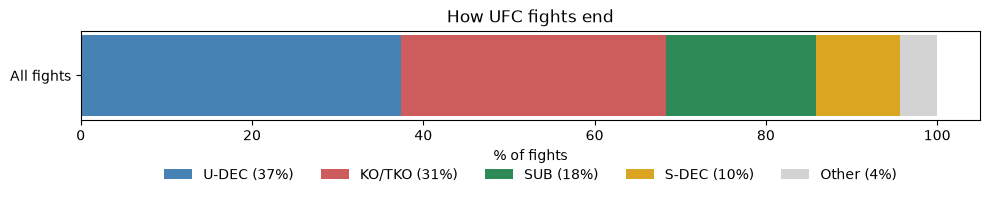

In [3]:
plot_share_bar(ufc["finish"], "How UFC fights end", save_as="images/finish_split.png")

Submissions make up 18%, the smallest of the three main finishes (S-DEC is split decision, still a decision), so I wanted to know what they actually look like. Which technique finishes the most fights?

## 2. Which submission is the most common?

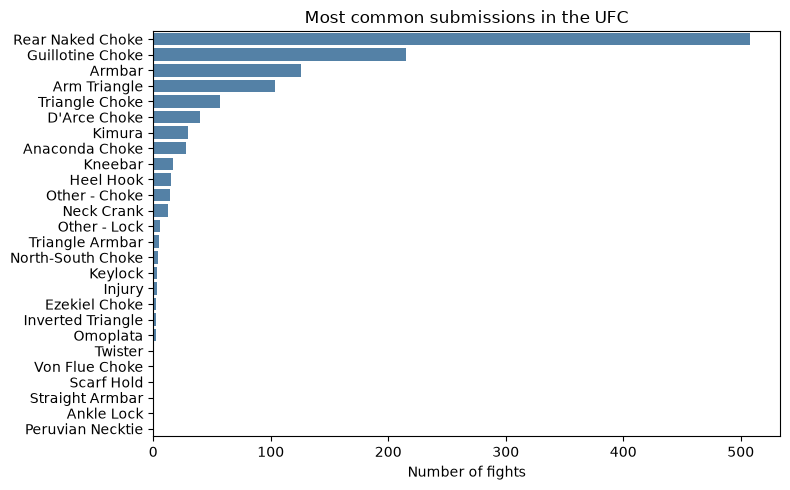

In [4]:
plot_counts(ufc[ufc["finish"] == "SUB"]["finish_details"],
            "Most common submissions in the UFC", top_n=26)

The rear-naked choke is by far the most common finish, accounting for over 40% of submissions, and chokes overall make up roughly 80%. A handful of techniques do most of the work. As a Peruvian, I’m proud to see the Peruvian necktie on the list, even with a single finish. It was back in the spotlight recently when Paddy Pimblett finished Benoit Saint-Denis with a hybrid between a D’Arce and a Peruvian necktie. That raises the next question: Who finishes fights by submission?

## 3. Who finishes fights by submission?

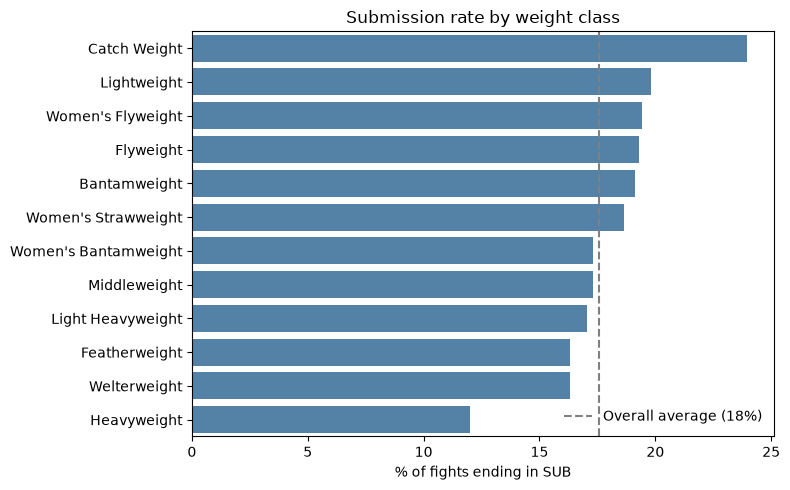

In [5]:
plot_rate_by_group(ufc, "weight_class", "SUB", "Submission rate by weight class")

Catch weight is excluded from this chart. It groups one-off bouts fought at agreed weights that don’t fit a standard division, and it has a small sample (about 70 fights), so a few submissions would swing its rate. The comparison here is between the standard weight classes.

About 1 in 5 lightweight fights ends in a submission (20%), compared with roughly 1 in 8 at heavyweight (12%). The overall average is 18%, so heavyweight is the real outlier. That raises the next question: are heavyweights simply more likely to end fights by knockout?

## 4. Are heavyweights simply more likely to end fights by knockout?

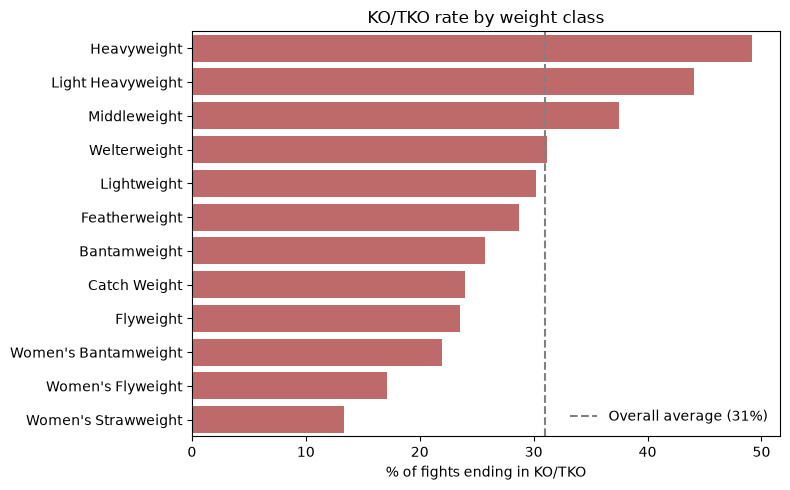

In [6]:
plot_rate_by_group(ufc, "weight_class", "KO/TKO", "KO/TKO rate by weight class", color="indianred", save_as="images/ko_by_class.png")

Nearly half of heavyweight fights (49.2%) end in a KO/TKO, compared with 23.5% at flyweight and 31% across all fights. The gap is much larger than for submissions, and the two charts mirror each other. Heavyweights have the most knockouts and the fewest submissions, while the lighter classes lean the other way. A likely explanation is that a single strike is more likely to end a heavyweight fight, but testing that would need strike-level data.

The women’s divisions are shown alongside the men’s, but they differ in two ways: they are the lightest weight classes, and they have fewer fights in the data. Weight and gender overlap here, so these charts can’t separate the effect of one from the other. The weight-class pattern is clearest among the men’s divisions.

In [7]:
weight_order = [
    "Women's Strawweight", "Flyweight", "Women's Flyweight", "Bantamweight", "Women's Bantamweight",
    "Featherweight", "Women's Featherweight", "Lightweight", "Welterweight",
    "Middleweight", "Light Heavyweight", "Heavyweight",
]

C:\Users\DELL\Documents\Portfolio\UFC\helpers.py:111: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  counts = df.assign(_finish=grouped).groupby([group_col, "_finish"]).size().unstack(fill_value=0)[order]


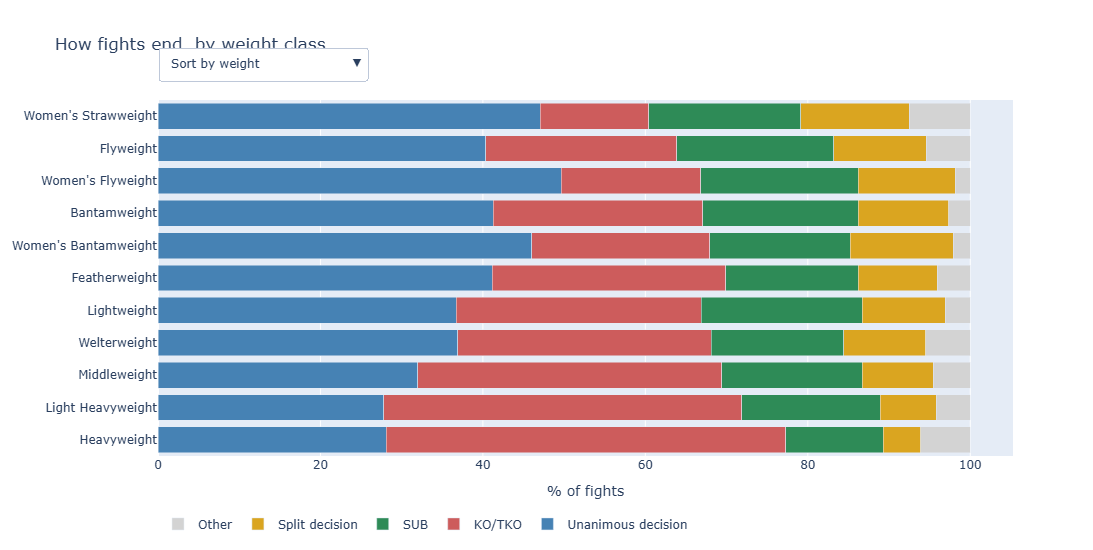

In [8]:
plot_finishes_by_group(
    ufc,
    exclude=["Catch Weight"],
    labels={"U-DEC": "Unanimous decision", "S-DEC": "Split decision"},
    weight_order=weight_order,
    save_html="images/finishes_by_class.html",
)

From light to heavy, decisions fade and knockouts grow, while submissions stay relatively steady.

## 5. Going back to submissions. Do lighter fighters actually attempt more submissions? 

C:\Users\DELL\Documents\Portfolio\UFC\helpers.py:163: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = df.assign(_value=df[value_cols].mean(axis=1))   # average of both fighters per fight


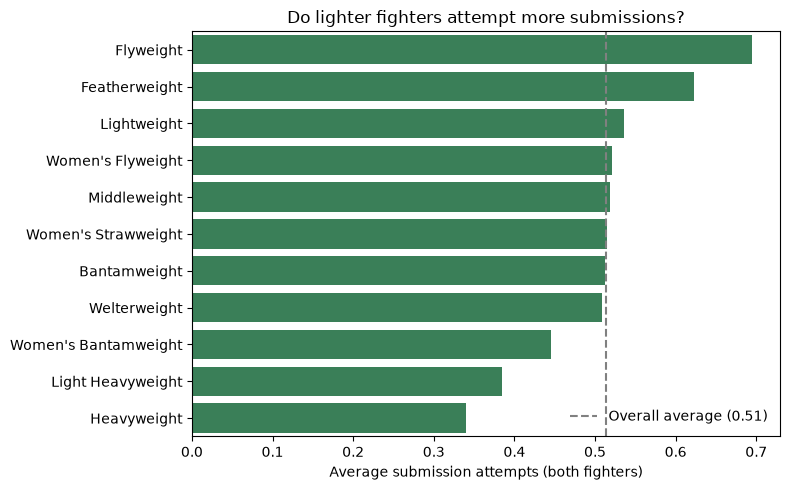

In [9]:
plot_avg_by_group(
    ufc, ["R_avg_SUB_ATT", "B_avg_SUB_ATT"],
    title="Do lighter fighters attempt more submissions?",
    xlabel="Average submission attempts (both fighters)",
    exclude=["Catch Weight"],
    save_as="images/sub_attempts.png",
)

Lighter fighters do attempt more submissions. Flyweights average about 0.7 attempts compared with 0.3 for heavyweights, against an overall average of 0.51. This fits the pattern from the finish charts, where lighter divisions end more fights by submission and heavyweights the fewest. The ranking isn’t perfectly ordered by weight, and some divisions (like featherweight) attempt a lot without finishing as often, so style is only part of the picture.

## 6. Is this pattern stable over time? 

C:\Users\DELL\Documents\Portfolio\UFC\helpers.py:186: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = df.assign(year=pd.to_datetime(df["date"]).dt.year)


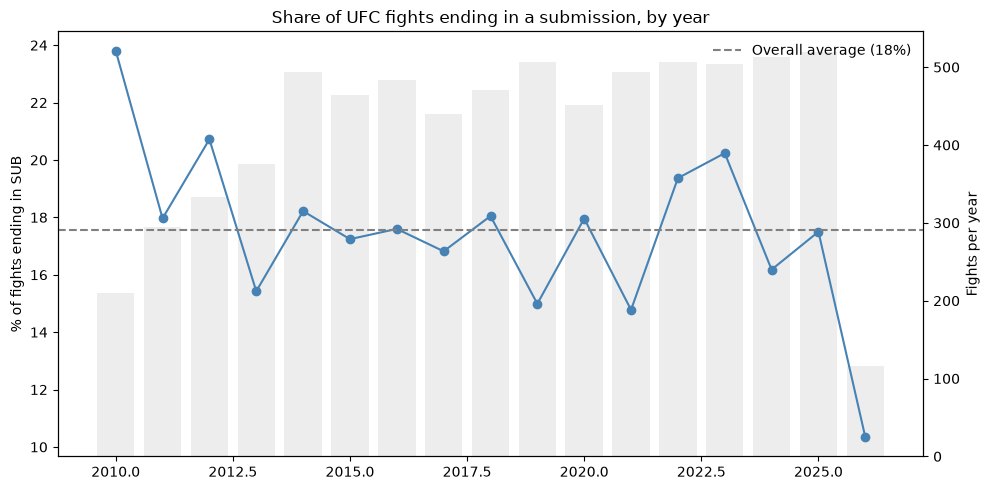

In [10]:
plot_rate_over_time(ufc, "SUB", "Share of UFC fights ending in a submission, by year",
                    save_as="images/sub_share_by_year.png")

Submissions have stayed remarkably steady over time. Since 2011, between roughly 15% and 20% of UFC fights each year have ended by submission, with no clear trend up or down. With about 500 fights per year, small swings from one year to the next are expected, so I wouldn’t read much into them. 2010 and 2026 have partial data, so I left them out of the conclusions.

## Conclusions

Submissions are the least common of the three main ways a UFC fight ends, at about 18% of fights, but they follow clear patterns. The rear-naked choke alone accounts for over 40% of them, and chokes overall make up roughly 80%.

Weight class shapes how fights end. About 1 in 5 lightweight fights ends in a submission (20%), compared with 12% at heavyweight. Knockouts show the opposite pattern and a much larger gap: KO/TKO ends 49.2% of heavyweight fights but only 23.5% of flyweight fights, against 31% overall. Decisions also become less common as the weight goes up. Lighter fighters also attempt more submissions, averaging about 0.7 attempts at flyweight and 0.3 at heavyweight, which fits the idea that style is part of the story.

These patterns aren’t a passing trend. Since 2011, the share of fights ending in a submission has stayed between about 15% and 20% every year, with no clear rise or decline.

Overall, the data suggests that weight class is a major factor in how fights end: lighter divisions lean toward submissions and decisions, and heavier divisions toward knockouts.